# Lecture 2 : Django: MVT Architecture

# Dr. Changjiiang Zhang
# CS, WKU
# Spring, 2025


As you already know, Django is a Python web framework. And like most modern framework, Django supports the MVC pattern. First let's see what is the Model-View-Controller (MVC) pattern, and then we will look at Django’s specificity for the Model-View-Template (MVT) pattern.

## MVC Pattern

When talking about applications that provides UI (web or desktop), we usually talk about MVC architecture (It is a design pattern). And as the name suggests, MVC pattern is based on three components: Model, View, and Controller
- Model: The lowest level of the pattern which is responsible for maintaining data.
- View: This is responsible for displaying all or a portion of the data to the user.
- Controller: Software Code that controls the interactions between the Model and View.


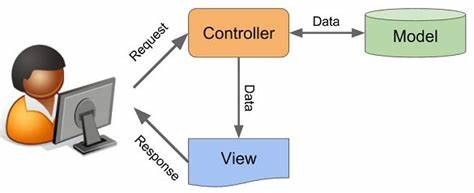

## DJANGO MVC - MVT Pattern

The Model-View-Template (MVT) is slightly different from MVC. In fact the main difference between the two patterns is that Django itself takes care of the Controller part (Software Code that controls the interactions between the Model and View), leaving us with the template. The template is a HTML file mixed with Django Template Language (DTL).
- **Model**: Model is going to act as the interface of your data. It is responsible for maintaining data. It is the logical data structure behind the entire application and is represented by a database (generally relational databases such as MySql, PostgreSQL).
- **View**: The View is the user interface — what you see in your browser when you render a webpage. It is represented by HTML/CSS/Javascript. 
    - A view function, or **view** for short, is a **Python function** that takes a Web request and returns a Web response. This response can be the HTML contents of a Web page, or a redirect, or a 404 error, or an XML document, or an image . . . or anything, really. The view itself contains whatever arbitrary logic is necessary to return that response.
- **Template**: A template consists of static parts of the desired HTML output as well as some special syntax describing how dynamic content will be inserted. 

Following is an architecture diagram for Django MVT:

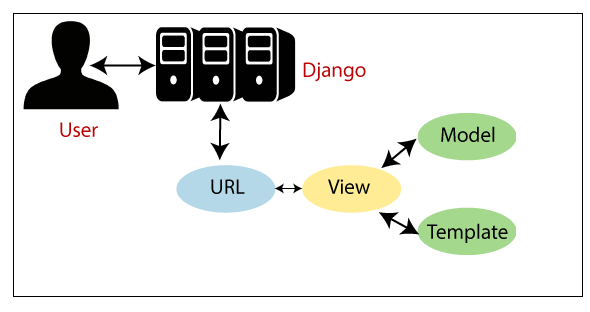

## MVT Workflow

Consider the hello world project we created:

``HelloWorld/
    HelloWorld/
        __init__.py
        asgi.py
        settings.py
        urls.py
        wsgi.py
    manage.py``

**Folder and file description**:
- ``HelloWorld``: the container for project,it actually contains two elements:
    - ``manage.py``: This file is kind of your project local django-admin for interacting with your project via command line (start the development server, sync db...). To get a full list of command accessible via manage.py you can use the code ``python manage.py help``
    - ``HelloWorld`` subfolder: This folder is the actual python package of your project. It contains four files
        - ``__init__.py``: Just for python, treat this folder as package.
        - ``asgi.py``: Asynchronous Server Gateway Interface
        - ``views.py``: the view we created.
        - ``settings.py``: As the name indicates, your project settings.
        - ``urls.py``: All links of your project and the function to call.
        - ``wsgi.py``: If you need to deploy your project over WSGI.


**Workflow**

- Step1: User type url in web broswer "127.0.0.1:8000"
- Step2: Django get the http request and perform URL dispatching (``urls.py``) 
    - Looks for the variable urlpatterns from ``urls.py`` module. This should be a sequence of django.urls.path() and/or django.urls.re_path() instances.
    - Django runs through each URL pattern, in order, and stops at the first one that matches the requested URL.
    - Once one of the URL patterns matches, Django imports and calls the given ``view`` in ``views.py``, which is a Python function.
- Step3: The mapped view will be invoked. The view itself contains **whatever arbitrary logic** is necessary to return that response. View can return an Response by **rendering a HTML Template**.
- Step4: The corresponding template will be rendered and display as the results.
    - A Django Template is a sequence of Text that helps in separation of the presentation layer of a document from its data.


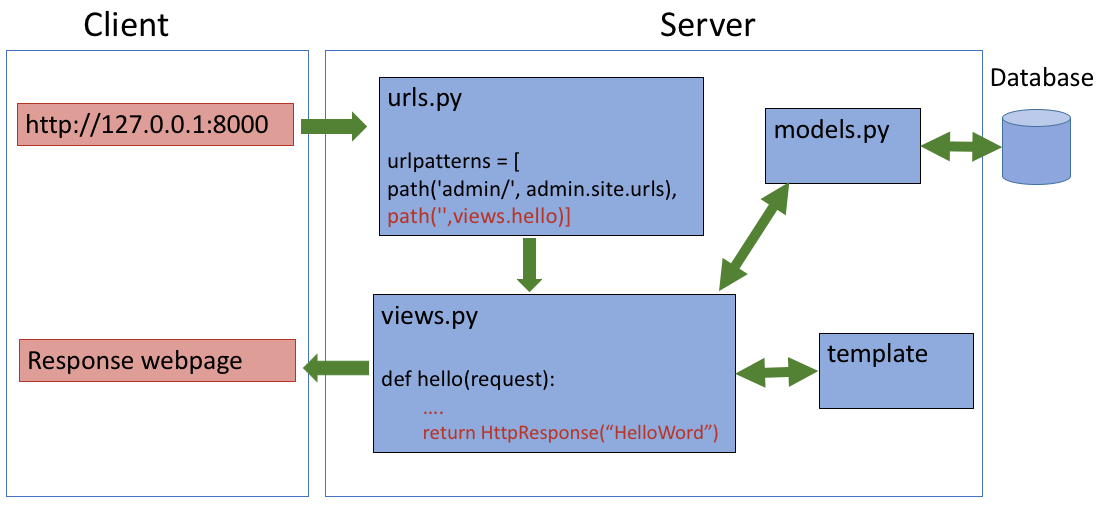


### MVT Code 

In previous view, we used the HTML response to render the HTML. This is not the most acceptable way. Django supports the MVT model, so we’ll need to render the previous view using template.

- First, we need a directory to store all the templates, this will help us in separating the design in a particular location. So create a new directory in you **project** and name it **templates**, i.e., D:\Django_project\HelloWorld\templates.

- Add a new html file ``hello.html``

In [ ]:
<html>
   <body>
      Hello World!!!<p>Today is {{today}}</p>
   </body>
</html>

**DTL (Django Template Language)**
The template engine of Django offers a mini-language to define the application’s user-facing layer:
- Displaying variable: ``{{variable}}``, a dictionary will passed by view function in the third argument (dictionary).
- Different tages (control purpose): ``{% if variable == 1 %}``, ``{% elif variable == 30 %}``, ``  {% for variable in list%}``....


refer to: https://docs.djangoproject.com/en/2.1/topics/templates/ for more information.

- Modify the ``TEMPLATES`` variable in file ``settings.py`` in the Hello World subfolder as follows:
'DIRS': [] =>  'DIR':[os.path.join(BASE_DIR,'templates')]

- import os module at the top 

In [ ]:
import os

TEMPLATES = [
    {
        'BACKEND': 'django.template.backends.django.DjangoTemplates',
        'DIRS': [os.path.join(BASE_DIR,'templates')],  # add the directory of template files
        'APP_DIRS': True,
        'OPTIONS': {
            'context_processors': [
                'django.template.context_processors.debug',
                'django.template.context_processors.request',
                'django.contrib.auth.context_processors.auth',
                'django.contrib.messages.context_processors.messages',
            ],
        },
    },
]

- Modify the ``views.py`` by adding a new view (function) called ``hello_tmp``:

In [ ]:
from django.http import HttpResponse
from django.shortcuts import render

import datetime

def hello(request):
    return HttpResponse("Hello world!")

def hello_tmp(request):
    today = datetime.datetime.now().date()
    return render(request,"hello.html",{"today":today}) # pass variable value via dict

``render()`` is a special Django helper function that creates a shortcut for communicating with a web browser. It works on three parameters:
- Request. it is the initial request.
- The path to the template. This is the direction in the project settings.py variables relative to the TEMPLATE DIRS option.
- Dictionary of parameters. A dictionary containing all the appropriate variables in the model. 

- Modify the urls.py to map the url to new view:

In [ ]:
from django.contrib import admin
from django.urls import path
from .  import views

urlpatterns = [
    path('admin/', admin.site.urls),
    path('',views.hello),
    path('hello/', views.hello_tmp) # new url mapping
]


Now, start your server 
- Type "http://127.0.0.1:8000", you will use hello view and get the http response as shown:

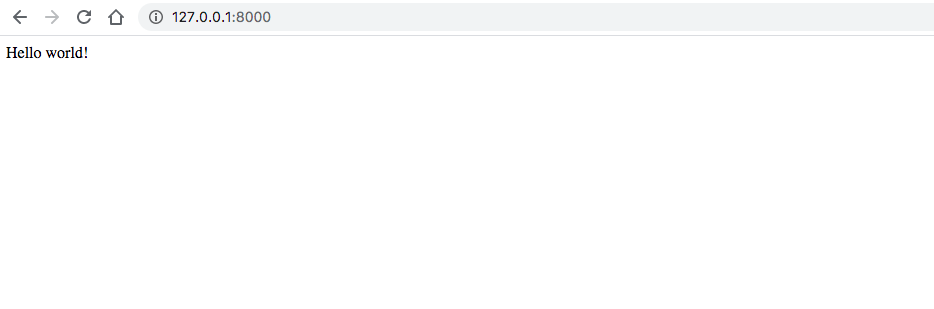

- Type "http://127.0.0.1:8000/hello/", you will use hello_tmp view and  get the rendered template as the result:



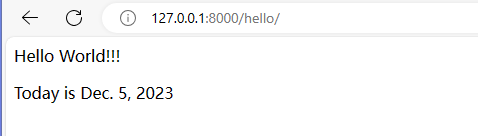

PyCharm demo for this project